# k-Means Part 2: Penguins

In [k-Means.ipynb](./k-Means.ipynb) we clustered tips data with no real way to check whether the clusters "meant" anything. This time we'll cluster penguin body measurements — but the penguins dataset also has a known `species` column (Adelie, Chinstrap, Gentoo) that k-Means never sees during fitting.

That gives us a fun unsupervised-vs-reality check: if we ask for 3 clusters, do they actually line up with the 3 real species?

# Import the libraries and dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

%matplotlib inline

In [2]:
df = pd.read_csv('data/penguins.csv')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


A few rows have missing measurements (see the all-NaN row near the top) — k-Means can't handle `NaN`s, so we drop them.

In [3]:
df.dropna(inplace=True)
df['species'].value_counts()

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

# Prepare the features

We only use the body-measurement columns — not `species`, `island`, or `sex` — since those would be cheating (or aren't numeric). We also **scale** the features this time: `body_mass_g` is in the thousands while `bill_depth_mm` is in the tens, and k-Means relies on Euclidean distance, so without scaling, body mass alone would dominate every distance calculation.

In [4]:
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Algorithm

There are 3 known penguin species, so let's start by asking k-Means for `k=3` and see what it finds on its own.

In [5]:
model = KMeans(n_clusters=3, n_init=10, random_state=42)
model.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 4)","[[-1.

In [6]:
model_predict = model.predict(X_scaled)
df['cluster'] = model_predict
df[['species', 'cluster']].head()

,species,cluster
0,Adelie,0
1,Adelie,0
2,Adelie,0
4,Adelie,0
5,Adelie,0


# Do the clusters match the species?

The cluster *numbers* (0, 1, 2) are arbitrary — k-Means has no idea the clusters should be called "Adelie" or "Gentoo". So instead of checking raw accuracy, we check two things:

1. A crosstab of `species` vs. `cluster` — does each species fall mostly into one cluster?
2. The **adjusted Rand index**, a metric made exactly for this — it measures agreement between two groupings while ignoring label numbering, and corrects for chance agreement. `1.0` means perfect agreement, `0.0` means random.

In [7]:
pd.crosstab(df['species'], df['cluster'])

cluster,0,1,2
species,,,
Adelie,124,0,22
Chinstrap,5,0,63
Gentoo,0,119,0


In [8]:
ari = adjusted_rand_score(df['species'], df['cluster'])
print(f'Adjusted Rand index: {ari:.3f}')

Adjusted Rand index: 0.799


# Visualize: predicted clusters vs. true species

`bill_length_mm` and `flipper_length_mm` happen to separate the species quite well visually, so we'll plot those two, colored first by k-Means' cluster assignment and then by the real species, side by side.

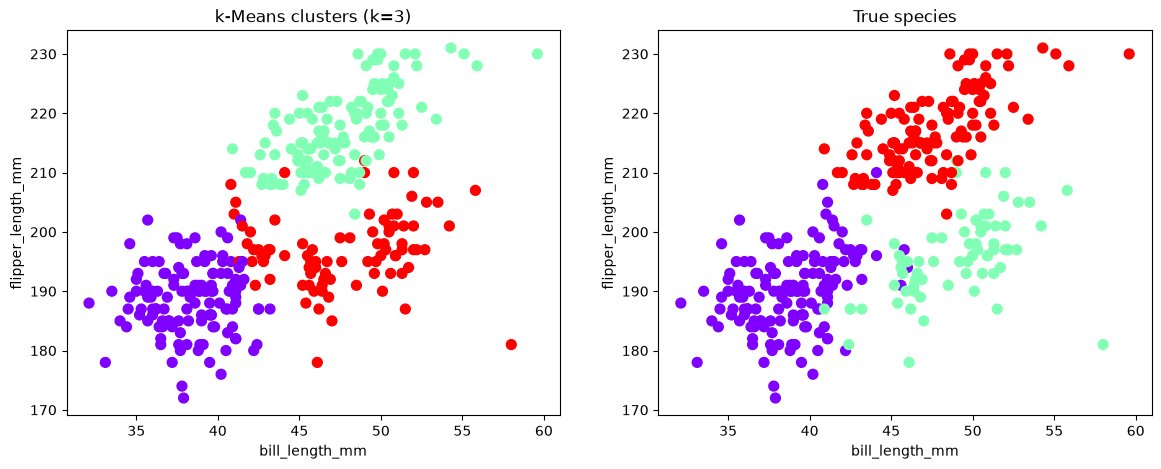

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(df['bill_length_mm'], df['flipper_length_mm'], c=df['cluster'], cmap='rainbow', s=50)
ax1.set_xlabel('bill_length_mm')
ax1.set_ylabel('flipper_length_mm')
ax1.set_title('k-Means clusters (k=3)')

species_codes = df['species'].astype('category').cat.codes
ax2.scatter(df['bill_length_mm'], df['flipper_length_mm'], c=species_codes, cmap='rainbow', s=50)
ax2.set_xlabel('bill_length_mm')
ax2.set_ylabel('flipper_length_mm')
ax2.set_title('True species')

plt.show()

# Scree plot: does the elbow suggest k=3?

Just like in [k-Means.ipynb](./k-Means.ipynb), let's check whether the elbow method — which has no idea there are 3 real species — happens to agree with the ground truth here.

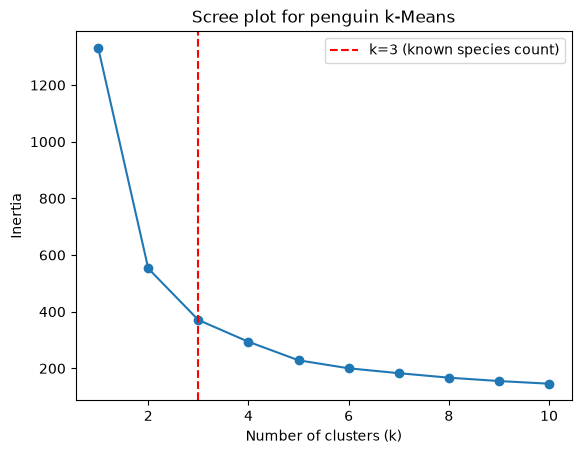

In [10]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    scree_model = KMeans(n_clusters=k, n_init=10, random_state=42)
    scree_model.fit(X_scaled)
    inertias.append(scree_model.inertia_)

plt.plot(k_values, inertias, marker='o')
plt.axvline(x=3, color='red', linestyle='--', label='k=3 (known species count)')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree plot for penguin k-Means')
plt.legend()
plt.show()

# Takeaways

- Unlike the tips dataset, here we had an actual ground truth (`species`) to grade the clustering against — the adjusted Rand index and crosstab above show just how well (or poorly) unsupervised k-Means recovered a real-world grouping it was never told about.
- Scaling mattered a lot: without `StandardScaler`, `body_mass_g` (values in the thousands) would have swamped the other three features in every distance calculation.
- The scree plot's elbow gives an *independent* signal for choosing k, with no access to species labels — comparing it to the true count of 3 is a nice sanity check on whether elbow-based choices are trustworthy in practice.